<a href="https://colab.research.google.com/github/pohlcriss/Aulas/blob/main/ProjetoTitanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Taxa de sobrevivência por sexo (0 = homem, 1 = mulher):
sex
0    0.188908
1    0.742038
Name: survived, dtype: float64

Taxa de sobrevivência por classe:
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


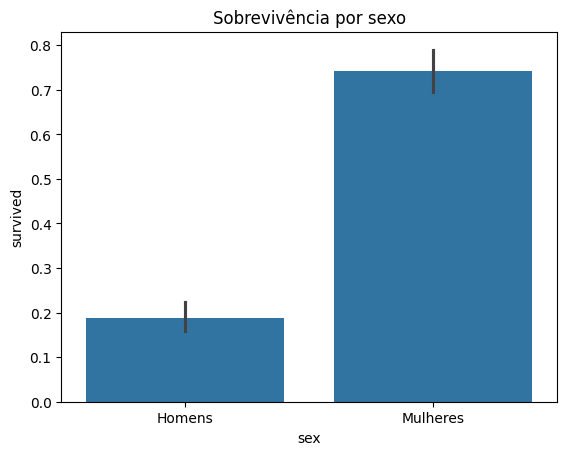

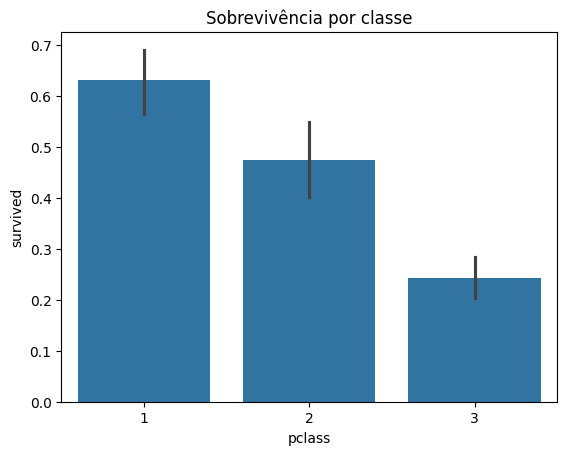


Acurácia: 0.7988826815642458
Matriz de confusão:
[[92 13]
 [23 51]]

Importância de cada variável:
sex       0.623887
pclass    0.235428
age       0.077610
fare      0.063075
dtype: float64


In [1]:
# =============================================================================
# PROJETO: PREVISÃO DE SOBREVIVÊNCIA NO TITANIC
# =============================================================================
#
# 1. DEFINIÇÃO DO PROBLEMA
# -----------------------------------------------------------------------------
# O naufrágio do Titanic (1912) causou a morte de mais de 1.500 pessoas.
# Sabe-se que a sobrevivência não foi aleatória: fatores como sexo, classe
# social e idade parecem ter influenciado quem teve acesso aos botes.
#
# Pergunta do projeto:
#   É possível prever se um passageiro sobreviveu a partir da sua classe,
#   sexo, idade e tarifa paga? E quais dessas características mais pesaram?
#
# Tipo de problema: classificação binária (0 = não sobreviveu, 1 = sobreviveu).
#
# 2. DADOS
# -----------------------------------------------------------------------------
# Fonte: dataset Titanic do repositório seaborn-data (formato CSV, via URL).
# Tamanho: 891 passageiros.
# Variáveis utilizadas:
#   - survived : alvo (0 = morreu, 1 = sobreviveu)
#   - pclass   : classe da passagem (1, 2 ou 3)
#   - sex      : sexo (male / female)
#   - age      : idade em anos
#   - fare     : valor pago pela passagem
#
# 3. PREPARAÇÃO E LIMPEZA
# -----------------------------------------------------------------------------
#   - Seleção apenas das colunas relevantes ao problema.
#   - Idades ausentes preenchidas com a MEDIANA (menos sensível a valores
#     extremos do que a média).
#   - A variável "sex" foi convertida para número (male = 0, female = 1),
#     pois o algoritmo só trabalha com valores numéricos.
#
# 4. ANÁLISE EXPLORATÓRIA
# -----------------------------------------------------------------------------
#   - Taxa de sobrevivência por sexo e por classe (tabelas e gráficos de barras).
#   - Observações: mulheres sobreviveram muito mais que homens, e a taxa de
#     sobrevivência diminui da 1ª para a 3ª classe.
#
# 5. MODELO
# -----------------------------------------------------------------------------
# Algoritmo: DecisionTreeClassifier (scikit-learn).
# Por que Árvore de Decisão? É fácil de interpretar: mostra quais variáveis
# foram usadas e em que ordem, o que facilita explicar o resultado.
#
# Decisões adotadas:
#   - Divisão treino/teste: 80% / 20% (train_test_split).
#   - random_state=42: garante que o resultado seja reproduzível.
#   - max_depth=3: limita a profundidade da árvore para evitar overfitting
#     (decorar os dados de treino e errar nos dados novos).
#
# 6. AVALIAÇÃO
# -----------------------------------------------------------------------------
# Métricas: acurácia e matriz de confusão.
#   - Acurácia obtida: [preencher após rodar]
#   - Referência (baseline): um modelo que sempre prevê "não sobreviveu"
#     acertaria cerca de 62% dos casos. O modelo precisa superar isso.
#   - Matriz de confusão: mostra quantos sobreviventes e não sobreviventes
#     foram classificados corretamente e onde o modelo errou.
#
# 7. INTERPRETAÇÃO DOS RESULTADOS E CONCLUSÕES
# -----------------------------------------------------------------------------
#   - Variável mais importante para o modelo: [preencher, provavelmente "sex"]
#   - O sexo e a classe da passagem foram os fatores mais associados à
#     sobrevivência, o que é coerente com a regra histórica de "mulheres e
#     crianças primeiro" e com o acesso diferenciado aos botes por classe.
#   - O modelo acertou [X]% dos casos de teste, contra ~62% do baseline.
#   - Limitações: poucas variáveis, dataset pequeno e idade preenchida com
#     mediana (pode distorcer a análise). Melhorias possíveis: usar mais
#     variáveis (família, porto de embarque), testar Random Forest e usar
#     validação cruzada.
#
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Carregando os dados
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
dados = pd.read_csv(url)

# 2. Limpeza: ficamos só com as colunas que vamos usar
dados = dados[["survived", "pclass", "sex", "age", "fare"]]

# Idade vazia vira a mediana
dados["age"] = dados["age"].fillna(dados["age"].median())

# Texto vira número (o modelo só entende números)
dados["sex"] = dados["sex"].map({"male": 0, "female": 1})

# 3. Análise exploratória
print("Taxa de sobrevivência por sexo (0 = homem, 1 = mulher):")
print(dados.groupby("sex")["survived"].mean())

print("\nTaxa de sobrevivência por classe:")
print(dados.groupby("pclass")["survived"].mean())

# 4. Gráficos
sns.barplot(data=dados, x="sex", y="survived")
plt.xticks([0, 1], ["Homens", "Mulheres"])
plt.title("Sobrevivência por sexo")
plt.show()

sns.barplot(data=dados, x="pclass", y="survived")
plt.title("Sobrevivência por classe")
plt.show()

# 5. Separando treino (80%) e teste (20%)
x = dados[["pclass", "sex", "age", "fare"]]
y = dados["survived"]
xTreino, xTeste, yTreino, yTeste = train_test_split(x, y, test_size=0.2, random_state=42)

# 6. Treinando a Árvore de Decisão
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(xTreino, yTreino)

# 7. Testando o modelo
previsoes = modelo.predict(xTeste)
print("\nAcurácia:", accuracy_score(yTeste, previsoes))
print("Matriz de confusão:")
print(confusion_matrix(yTeste, previsoes))

# 8. O que mais pesou na decisão?
importancias = pd.Series(modelo.feature_importances_, index=x.columns)
print("\nImportância de cada variável:")
print(importancias.sort_values(ascending=False))